In [55]:
#import all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [56]:
#Read and show the file 
df = pd.read_csv(r"C:\pp\ml--2026\tsv\Cars.csv")
df.head()

,carname,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130.0,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130.0,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152.0,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109.0,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136.0,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [57]:
#Determine the dataset dimension
df.shape

(205, 24)

In [58]:
#use describe function for qualatitve columns
df.describe(include = ["object"])

,carname,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,enginetype,cylindernumber,fuelsystem
count,205,205,205,205,205,205,205,205,205,205
unique,147,2,2,2,5,3,2,7,7,8
top,toyota corona,gas,std,four,sedan,fwd,front,ohc,four,mpfi
freq,6,185,168,115,96,120,202,148,159,94


In [59]:
#use describe function for quantitative columns
df.describe(exclude = ["object"])

,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,194.000000,205.000000,185.000000,190.000000,205.000000,185.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,98.669588,174.049268,65.932973,53.738947,2555.565854,124.081081,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,5.934168,12.337289,2.113143,2.470452,520.680204,38.528771,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,94.500000,166.300000,64.200000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,97.000000,173.200000,65.500000,54.100000,2414.000000,110.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,101.800000,183.100000,66.600000,55.575000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,120.900000,208.100000,72.300000,59.800000,4066.000000,308.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


# Q1: How many null values are there in each column?


In [60]:
df.isna().sum()

carname              0
fueltype             0
aspiration           0
doornumber           0
carbody              0
drivewheel           0
enginelocation       0
wheelbase           11
carlength            0
carwidth            20
carheight           15
curbweight           0
enginetype           0
cylindernumber       0
enginesize          20
fuelsystem           0
boreratio            0
stroke               0
compressionratio     0
horsepower           0
peakrpm              0
citympg              0
highwaympg           0
price                0
dtype: int64

# Q1_1: Replace the null value of column "wheelbase" with the max value of the same column

In [61]:
max_wheelbase = df["wheelbase"].max
df["wheelbase"].fillna(max_wheelbase)

0       88.6
1       88.6
2       94.5
3       99.8
4       99.4
       ...  
200    109.1
201    109.1
202    109.1
203    109.1
204    109.1
Name: wheelbase, Length: 205, dtype: object

# Q1_2: Replace the null value of column "carwidth" with the Min value of the same column

In [62]:
min_carwidth = df["carwidth"].min
df["carwidth"].fillna(min_carwidth)

0      64.1
1      64.1
2      65.5
3      66.2
4      66.4
       ... 
200    68.9
201    68.8
202    68.9
203    68.9
204    68.9
Name: carwidth, Length: 205, dtype: object

# Q1_3: Use Linear Interpolation to change the null value of column "carheight"


In [63]:
df["carheight"] = df["carheight"].interpolate(method='linear')
df["carheight"].isnull().sum()

np.int64(0)

# Q1_4: Replace the null value of column "enginesize" with the mod of the same column and check how many null values we have

In [64]:
engine_mode = df["enginesize"].mode()[0]
df["enginesize"] = df["enginesize"].fillna(engine_mode)
df['enginesize'].isnull().sum()

np.int64(0)

# Q2: What is the Probability that the Car is Sedan ? (1 mark)

In [65]:
total_cars = len(df)
print(total_cars)

sedan = len(df[df['carbody'] == 'sedan'])
print(sedan/total_cars)

205
0.4682926829268293


# Q3: What is the Probability that the car is Sedan and works with gas ?


In [66]:
sedan_gas_count = len(df[(df['carbody'] == 'sedan') & (df['fueltype'] == 'gas')])
print(sedan_gas_count / total_cars)

0.3951219512195122


# Q4:What is the probability that a car is Sedan given it is a gas fuel type?

In [67]:
gas = df[df['fueltype'] == 'gas']
sedan_given_gas= len(gas[gas['carbody'] == 'sedan'])

print(sedan_given_gas_count / len(gas))



0.43783783783783786


# Q5: Given that the car height is higer than 50, find the probability that the car engin size is greater than 130?

In [68]:
tall_cars = df[df['carheight'] > 50]
large_engine = len(tall_cars[tall_cars['enginesize'] > 130])

print( large_engine / len(tall_cars))

0.2916666666666667


# Part 2: Probability Functions


# Q6: Load dataset 'students.csv' and show first rows, shape, and compute the skewness.


In [84]:
df2 = pd.read_csv(r"C:\pp\ml--2026\tsv\students.csv")
df2.head()

,stud.id,name,gender,age,height,weight,religion,nc.score,semester,major,minor,score1,score2,online.tutorial,graduated,salary
0,833917,"Gonzales, Christina",Female,19,160,64.8,Muslim,1.91,1st,Political Science,Social Sciences,NaN,NaN,0,0,NaN
1,898539,"Lozano, T'Hani",Female,19,172,73.0,Other,1.56,2nd,Social Sciences,Mathematics and Statistics,NaN,NaN,0,0,NaN
2,379678,"Williams, Hanh",Female,22,168,70.6,Protestant,1.24,3rd,Social Sciences,Mathematics and Statistics,45.0,46.0,0,0,NaN
3,807564,"Nem, Denzel",Male,19,183,79.7,Other,1.37,2nd,Environmental Sciences,Mathematics and Statistics,NaN,NaN,0,0,NaN
4,383291,"Powell, Heather",Female,21,175,71.4,Catholic,1.46,1st,Environmental Sciences,Mathematics and Statistics,NaN,NaN,0,0,NaN


In [85]:
df2.shape

(8239, 16)

In [86]:
print(df2.skew(numeric_only=True))

stud.id            0.018612
age                4.427823
height            -0.009244
weight             0.651004
nc.score           0.446834
score1            -0.318819
score2            -0.304878
online.tutorial    0.467502
graduated          1.403900
salary             0.273835
dtype: float64


# Q7: What is the probability that the salary is greater than 20000 and less than 30000 ?


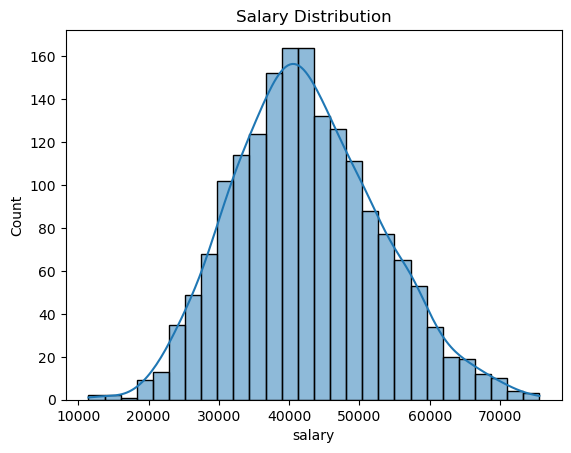

0.273835141614412


In [87]:
# 1.1) Plotting Histogram
sns.histplot(df2['salary'], kde=True)
plt.title('Salary Distribution')
plt.show()

# 1.2) Calculate the skewness
skew_val = df2['salary'].skew()
print(skew_val)

In [89]:
# 2) Compute mean and std
mu = df2['salary'].mean()
sigma = df2['salary'].std()

print(mu)
print(sigma)

42522.112364181405
10333.139905547341


In [90]:
# 3) Convert to Z-scores
z1 = (20000 - mu) / sigma
z2 = (30000 - mu) / sigma

print(z1)
print(z2)

-2.1796000605866586
-1.2118400097785296


In [ ]:
# 4) Calculate the probability using scipy.stats.norm.cdf
# Cumulative Distribution Function
from scipy import stats
prob = stats.norm.cdf(z2) - stats.norm.cdf(z1)

print(prob)

0.09814325462173674


# Q8: A factory produces 200 chips with defect rate 8%. Answer the following questions:

In [96]:
from scipy.stats import binom

# Define parameters
n = 200
p = 0.08

# 2) Probability of exactly 14 defective chips
prob_exactly_14 = binom.pmf(14, n, p)
print(prob_exactly_14)

# 3) At least 14 defective chips (P(X >= 14))
prob_at_least_14 = 1 - binom.cdf(13, n, p)
print(prob_at_least_14)

# 4) At most 15 defective chips (P(X <= 15))
prob_at_most_15 = binom.cdf(15, n, p)
print(prob_at_most_15)

# 5) Expected defects and standard deviation
expected_value = n * p
std_dev = (n * p * (1 - p))**0.5

print(expected_value)
print(std_dev)

0.0954115649226197
0.7357078859493741
0.4625822359332888
16.0
3.8366652186501757


In [ ]:
# 3) Convert to Z-scores
z1 = (20000 - mu) / sigma
z2 = (30000 - mu) / sigma

print(f"Z-score for 20000: {z1}")
print(f"Z-score for 30000: {z2}")